# 3. Az LSTM-hibrid: újraszámolás egy rövid szakaszon

Az LSTM-család modellje: **előrejelzés = HAR-X (ugyanaz az OLS) + LSTM-korrekció**. Egy teljes LSTM-modell futása 1–2 óra,
ezért itt csak egy rövid szakaszt (alapból 3 újrabecslést) számolunk újra, és összevetjük a tárolt előrejelzéssel.

**Miért egyezik pontosan?** Az LSTM negyedévente nulláról, rögzített véletlenmaggal (seed) indul („cold start”),
közben az előző súlyokból folytatja. Ha a szakaszt egy ilyen nulláról induló újrabecslésnél kezdjük, a számítás
pontosan megismételhető. Ezért a notebook a kiválasztott dátum utáni első ilyen pontot keresi meg.

In [1]:
# A projekt gyökerének megkeresése és a közös motor (src/) betöltése
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("projekt:", ROOT)

projekt: C:\Users\Tamás\Thesis_V3


In [2]:
LEPCSO = "L1"
TRANSZF = "Log"
ABLAK = "2Y"
GYAKORISAG = "Monthly"   # Monthly: gyorsabb (3 újrabecslés ≈ 3 hónap); Weekly: 3 újrabecslés ≈ 3 hét
MERTEK = "RV"
DATUM = "2020-02-01"     # a szakasz ennél a dátumnál vagy utána kezdődik (2020 eleje: COVID)
UJRABECSLESEK = 3        # hány újrabecslést számoljunk újra (Monthly-nál kb. 20 mp / újrabecslés)

In [3]:
import time
import torch
from config import LSTM_PARAMS, WINDOWS, model_dir
from forecasting import load_model_data, refit_flags
from lstm import walk_forward

torch.set_num_threads(1)             # a teljes futás is így készült (egy modell = egy processzormag)

X, y, sigma, dates, nevek = load_model_data(LEPCSO, TRANSZF, MERTEK)
w = WINDOWS[ABLAK]
refit = refit_flags(dates, GYAKORISAG)
ujrabecslesek = [i for i in range(w, len(dates)) if i == w or refit[i]]
cold = LSTM_PARAMS["cold_every"][GYAKORISAG]
k = next(k for k in range(0, len(ujrabecslesek), cold) if dates[ujrabecslesek[k]] >= pd.Timestamp(DATUM))
start, stop = ujrabecslesek[k], ujrabecslesek[min(k + UJRABECSLESEK, len(ujrabecslesek) - 1)]
print(f"szakasz: {dates[start].date()} – {dates[stop - 1].date()}  ({stop - start} nap, {UJRABECSLESEK} újrabecslés)")

t0 = time.time()
mu, s2, mu_lin = walk_forward(X, y, dates, w, GYAKORISAG, start=start, stop=stop)
print(f"futási idő: {time.time() - t0:.0f} mp")

szakasz: 2020-02-03 – 2020-04-30  (61 nap, 3 újrabecslés)


futási idő: 15 mp


In [4]:
mappa = model_dir("LSTM", LEPCSO, TRANSZF, ABLAK, GYAKORISAG, MERTEK)
fc = pd.read_csv(mappa / "forecasts.csv", index_col="date", parse_dates=True)
lin = pd.read_csv(mappa / "linear_part.csv", index_col="date", parse_dates=True)
har = pd.read_csv(model_dir("HAR", LEPCSO, TRANSZF, ABLAK, GYAKORISAG, MERTEK) / "forecasts.csv", index_col="date", parse_dates=True)
d = dates[start:stop]

print("újraszámolt vs. tárolt LSTM-előrejelzés, legnagyobb eltérés:", np.max(np.abs(mu[start:stop] - fc.loc[d, "y_hat"].to_numpy())))
print("újraszámolt lineáris rész vs. a HAR-X modell előrejelzése:  ", np.max(np.abs(mu_lin[start:stop] - har.loc[d, "y_hat"].to_numpy())))
szakasz = pd.DataFrame({"HAR-X rész": mu_lin[start:stop], "LSTM-korrekció": mu[start:stop] - mu_lin[start:stop],
                        "előrejelzés": mu[start:stop], "tárolt": fc.loc[d, "y_hat"].to_numpy()}, index=d)
szakasz.head(10)

újraszámolt vs. tárolt LSTM-előrejelzés, legnagyobb eltérés: 8.881784197001252e-16
újraszámolt lineáris rész vs. a HAR-X modell előrejelzése:   8.881784197001252e-16


,HAR-X rész,LSTM-korrekció,előrejelzés,tárolt
date,,,,
2020-02-03,-3.785717,0.0,-3.785717,-3.785717
2020-02-04,-3.766044,0.0,-3.766044,-3.766044
2020-02-05,-3.721773,0.0,-3.721773,-3.721773
2020-02-06,-3.733693,0.0,-3.733693,-3.733693
2020-02-07,-3.874590,0.0,-3.874590,-3.874590
2020-02-10,-3.873258,0.0,-3.873258,-3.873258
2020-02-11,-3.967338,0.0,-3.967338,-3.967338
2020-02-12,-3.957226,0.0,-3.957226,-3.957226
2020-02-13,-3.921806,0.0,-3.921806,-3.921806


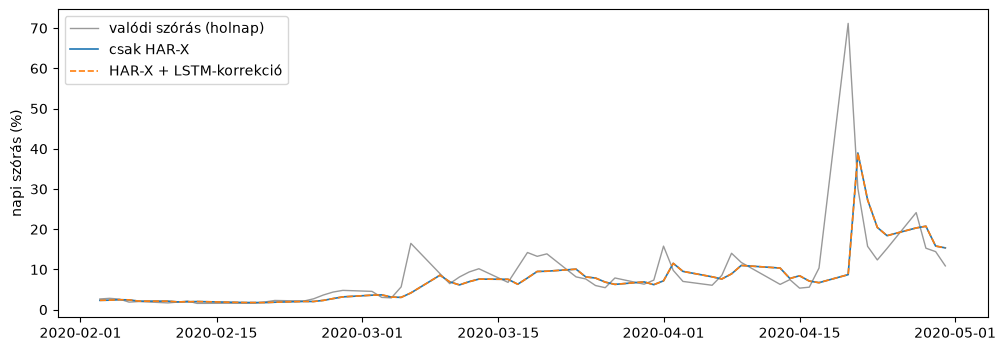

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d, sigma[start:stop] * 100, color="0.6", lw=1, label="valódi szórás (holnap)")
ax.plot(d, np.exp(mu_lin[start:stop] + s2[start:stop] / 2) * 100 if TRANSZF == "Log" else (np.maximum(mu_lin[start:stop], 0) ** 2 + s2[start:stop]) * 100,
        lw=1.2, label="csak HAR-X")
ax.plot(d, fc.loc[d, "sigma_hat"] * 100, lw=1.2, ls="--", label="HAR-X + LSTM-korrekció")
ax.set_ylabel("napi szórás (%)")
ax.legend()
plt.show()

## A korrekció a teljes modellben

Ha a korai leállítás a validációs részen nem talál javulást, a háló a nulla kezdőállapotában marad: ilyenkor a korrekció
pontosan nulla, és az előrejelzés megegyezik a HAR-X-szel.

napok, ahol a korrekció pontosan 0: 71.2%
a korrekció abszolút értékének átlaga (transzformált skálán): 0.0035


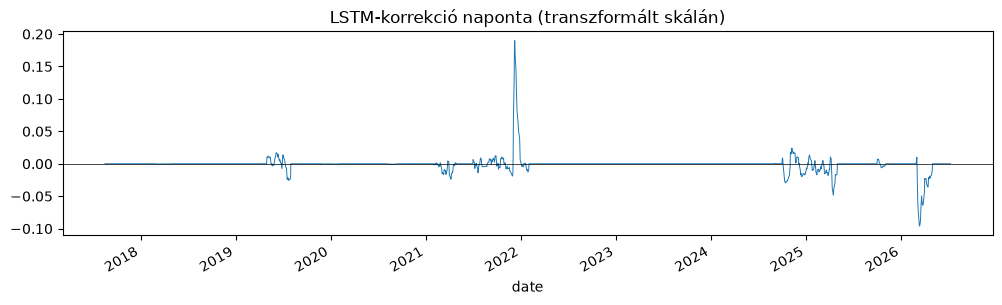

In [6]:
korr = fc["y_hat"] - lin.loc[fc.index, "y_lin"]
print(f"napok, ahol a korrekció pontosan 0: {(korr.abs() < 1e-12).mean():.1%}")
print(f"a korrekció abszolút értékének átlaga (transzformált skálán): {korr.abs().mean():.4f}")
ax = korr.plot(figsize=(12, 3), lw=0.7, title="LSTM-korrekció naponta (transzformált skálán)")
ax.axhline(0, color="k", lw=0.5)
plt.show()